# Figure 8-5 — Monte Carlo

Passives are drawn independently and uniformly inside their tolerance
boxes. The AC study uses 2000 draws, seed 42, and includes offset and bias
current. That run is stored under `results/mc_ac/` and is separate from the
transient run.

The transient study uses 500 draws, seed 42, on the passives only. The same
draws are solved analytically, in ngspice, and in LTspice. Histograms share
one set of bins so the three solvers can be compared.

Created with Grok Build.


In [1]:
import sys

import os
os.environ["MPLBACKEND"] = "Agg"
import matplotlib
matplotlib.use("Agg", force=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import io
from pathlib import Path
from IPython.display import display, Image

def _show(*args, **kwargs):
    buf = io.BytesIO()
    fig = plt.gcf()
    fig.savefig(buf, format="png", dpi=150, bbox_inches="tight")
    plt.close("all")
    display(Image(data=buf.getvalue()))

plt.show = _show

def _find_project_root():
    start = Path.cwd().resolve()
    named = Path("Sections/Electronics/Analog_and_Digital/OPA365_Fig85")
    candidates = [start, *start.parents, start / named]
    if start.name == "notebooks":
        candidates.insert(0, start.parent)
    for cand in candidates:
        if (cand / "mfb_design" / "__init__.py").is_file():
            return cand
    raise FileNotFoundError("mfb_design package was not found")

ROOT = _find_project_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


In [2]:
from mfb_design.params import CircuitParams, ToleranceSpec

p = CircuitParams(
    R1=549.0,
    R2=1.24e3,
    R3=549.0,
    C1=1.0e-9,
    C2=150.0e-12,
    r_tol=ToleranceSpec(0.001),
    c_tol=ToleranceSpec(0.01),
)
SPICE_WORKERS = 4
N_MC_AC = 2000
N_MC_TRAN = 500
MC_SEED = 42
print(
    f"R1={p.R1:g} ohm  R2={p.R2:g} ohm  R3={p.R3:g} ohm  "
    f"C1={p.C1:g} F  C2={p.C2:g} F"
)
print(
    f"supplies {p.op.v_pos:g} V / {p.op.v_neg:g} V, "
    f"tone {p.op.f_passband_hz:g} Hz, {p.op.v_in_peak:g} V peak"
)
FIG = ROOT / "results" / "figures"
FIG.mkdir(parents=True, exist_ok=True)


R1=549 ohm  R2=1240 ohm  R3=549 ohm  C1=1e-09 F  C2=1.5e-10 F
supplies 2.5 V / -2.5 V, tone 250000 Hz, 1 V peak


In [3]:
import json
from mfb_design.analysis import find_fc_3db
from mfb_design.monte_carlo import annotate_wc_rss_on_axis, sample_metrics
from mfb_design.worst_case import rss_bounds

mc = sample_metrics(p, n=N_MC_AC, seed=MC_SEED, include_opamp=True)
out = ROOT / "results" / "mc_ac"
out.mkdir(parents=True, exist_ok=True)
mc.frame.to_csv(out / "samples.csv", index=False)
(out / "meta.json").write_text(json.dumps({
    "kind": "mc_ac",
    "n": N_MC_AC,
    "seed": MC_SEED,
}, indent=2), encoding="utf-8")
display(mc.summary)

names = list(p.passive_dict())
fc_corners = []
for mask in range(1 << len(names)):
    kw = {}
    for bit, name in enumerate(names):
        lo, hi = p.tol_for(name).bounds(getattr(p, name))
        kw[name] = lo if (mask >> bit) & 1 else hi
    fc_corners.append(find_fc_3db(p.with_values(**kw)))
wc_lo, wc_hi = min(fc_corners), max(fc_corners)
rss = rss_bounds(p, metrics=("fc_hz",), include_opamp=False)["fc_hz"]
print(
    f"AC draws {len(mc.frame)}, fc mean {mc.frame['fc_hz'].mean():.1f} Hz, "
    f"std {mc.frame['fc_hz'].std():.1f} Hz"
)
print(f"32-corner fc {wc_lo:.1f} to {wc_hi:.1f} Hz, RSS ±{rss['delta_rss']:.1f} Hz")


AC draws 2000, fc mean 495397.0 Hz, std 2874.1 Hz
32-corner fc 489462.6 to 501291.4 Hz, RSS ±5010.1 Hz


,mean,std,min,max,p01,p05,p50,p95,p99
fc_hz,495397,2874.11,489827,500785,490326,490967,495367,499798,500352
passband_gain,1.00001,0.000819907,0.99808,1.00198,0.998244,0.998635,1.00001,1.00137,1.00171
gain_at_fdesign,0.700615,0.00404962,0.692883,0.708685,0.693607,0.69429,0.70057,0.706863,0.707674
phase_at_fdesign_deg,89.6855,0.333515,88.8912,90.4862,89.0036,89.1283,89.6892,90.2495,90.3896
gain_at_passband,0.967253,0.00203644,0.961634,0.972596,0.962832,0.963809,0.967286,0.970598,0.971399
phase_at_passband_deg,136.347,0.228581,135.85,136.841,135.924,135.984,136.346,136.706,136.777
dc_vout,-1.00001,0.000848573,-1.00221,-0.997866,-1.00183,-1.00139,-1.00001,-0.998575,-0.99818
dc_error,2.38594e-06,0.000229359,-0.000399251,0.000399777,-0.000393156,-0.000359165,7.57056e-06,0.000359459,0.000390449
gain_error,-1.07124e-05,0.000848573,-0.0022095,0.00213393,-0.00182603,-0.00139041,-1.08317e-05,0.00142543,0.00182045


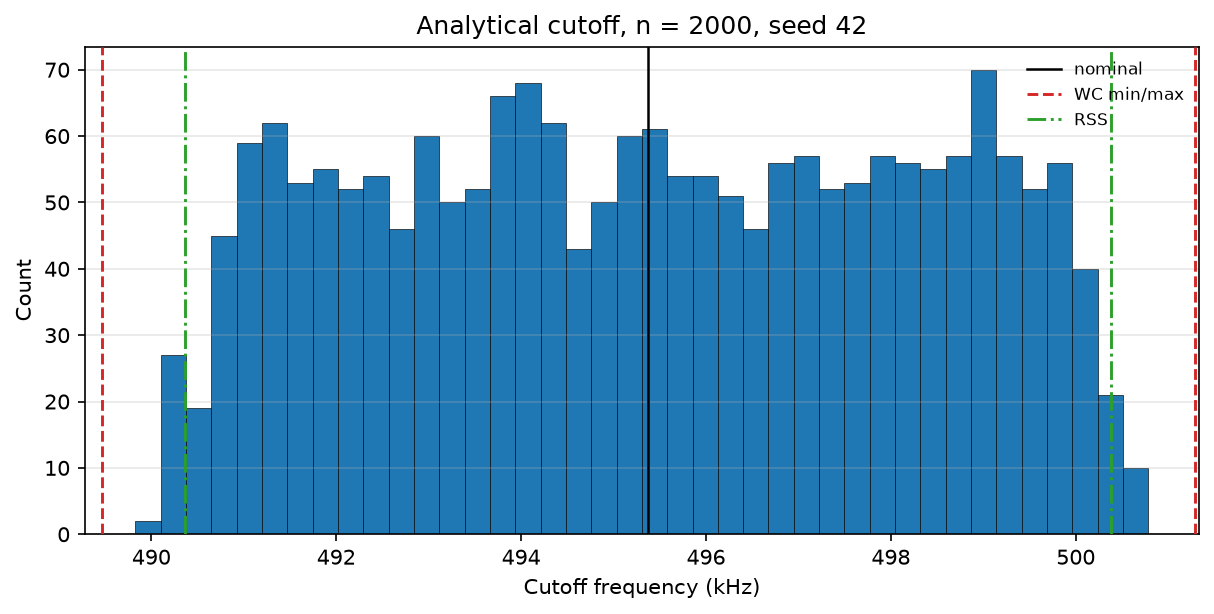

In [4]:
fig, ax = plt.subplots(figsize=(8.2, 4.2))
ax.hist(mc.frame["fc_hz"] / 1e3, bins=40, color="C0", edgecolor="k", linewidth=0.3)
annotate_wc_rss_on_axis(
    ax,
    wc_low=wc_lo / 1e3,
    wc_high=wc_hi / 1e3,
    rss_low=rss["low"] / 1e3,
    rss_high=rss["high"] / 1e3,
    nominal=find_fc_3db(p) / 1e3,
)
ax.set_xlabel("Cutoff frequency (kHz)")
ax.set_ylabel("Count")
ax.set_title(f"Analytical cutoff, n = {N_MC_AC}, seed {MC_SEED}")
ax.grid(True, axis="y", alpha=0.3)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "05_mc_ac_fc.png", dpi=150)
plt.show()


## 500-run transient

The cache is `results/mc_tran.csv`. Gain and phase histograms use one bin
set for the analytical model, ngspice, and LTspice. Vertical lines on the
gain plots are the minimum and maximum of the 32-corner hypercube.


In [5]:
from mfb_design.transient import load_or_run_mc, summary_table

tran = load_or_run_mc(
    p,
    root=ROOT,
    cache_csv=ROOT / "results" / "mc_tran.csv",
    n=N_MC_TRAN,
    seed=MC_SEED,
    workers=SPICE_WORKERS,
)
if not bool(tran["ng_ok"].all()) or tran["lt_gain"].isna().any():
    raise RuntimeError("transient Monte Carlo cache is incomplete")
display(summary_table(tran, [
    ("analytical gain", "an_gain"),
    ("ngspice gain", "ng_gain"),
    ("LTspice gain", "lt_gain"),
    ("analytical phase deg", "an_phase_deg"),
    ("ngspice phase deg", "ng_phase_deg"),
    ("LTspice phase deg", "lt_phase_deg"),
]))
ng_err = float((tran["ng_gain"] - tran["an_gain"]).abs().max())
lt_err = float((tran["lt_gain"] - tran["an_gain"]).abs().max())
print(f"max |ngspice − analytical| gain = {ng_err:.3e}")
print(f"max |LTspice − analytical| gain = {lt_err:.3e}")
if ng_err > 1e-3 or lt_err > 1e-3:
    raise RuntimeError("a solver disagrees with the analytical Monte Carlo gain")
hc = pd.read_csv(ROOT / "results" / "hypercube_tran.csv")


max |ngspice − analytical| gain = 4.422e-05
max |LTspice − analytical| gain = 1.049e-04


result,mean,std,min,p05,p95,max
analytical gain,0.967161,0.00206771,0.962302,0.963955,0.970682,0.972356
ngspice gain,0.967119,0.00206875,0.962259,0.963911,0.970642,0.972317
LTspice gain,0.967105,0.0020678,0.9622,0.9639,0.970605,0.9723
analytical phase deg,136.347,0.234152,135.843,135.97,136.716,136.831
ngspice phase deg,136.331,0.234219,135.827,135.954,136.701,136.815
LTspice phase deg,136.346,0.234226,135.84,135.97,136.72,136.83


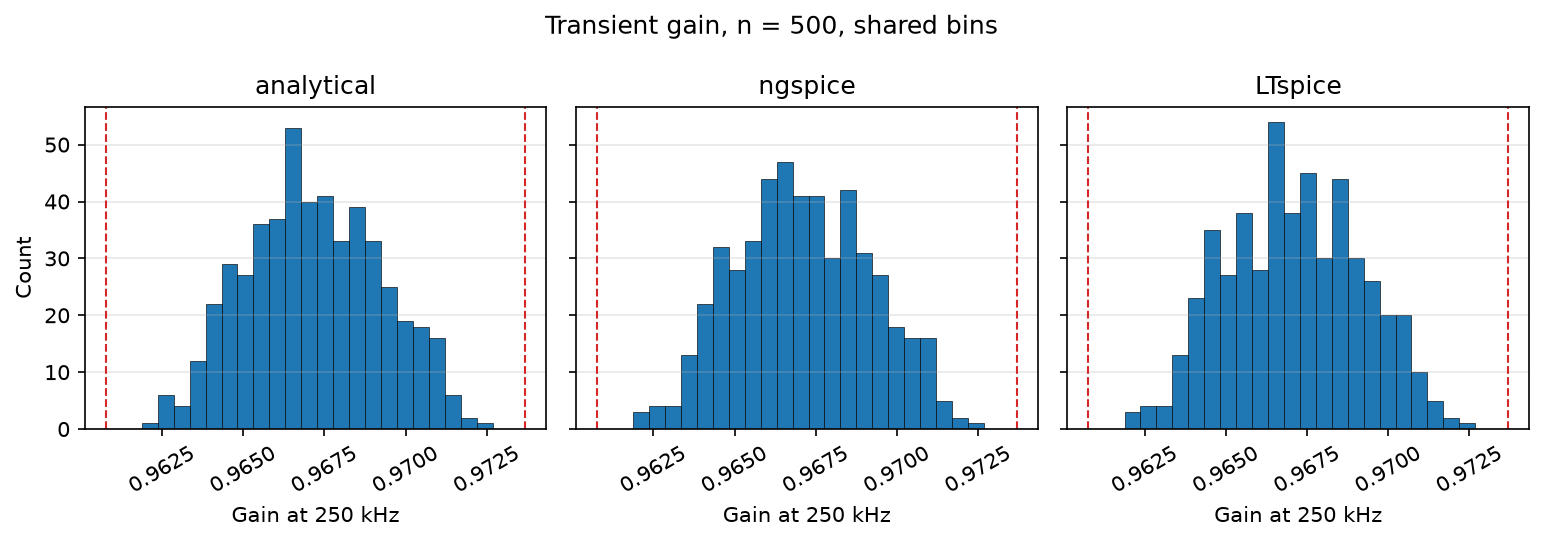

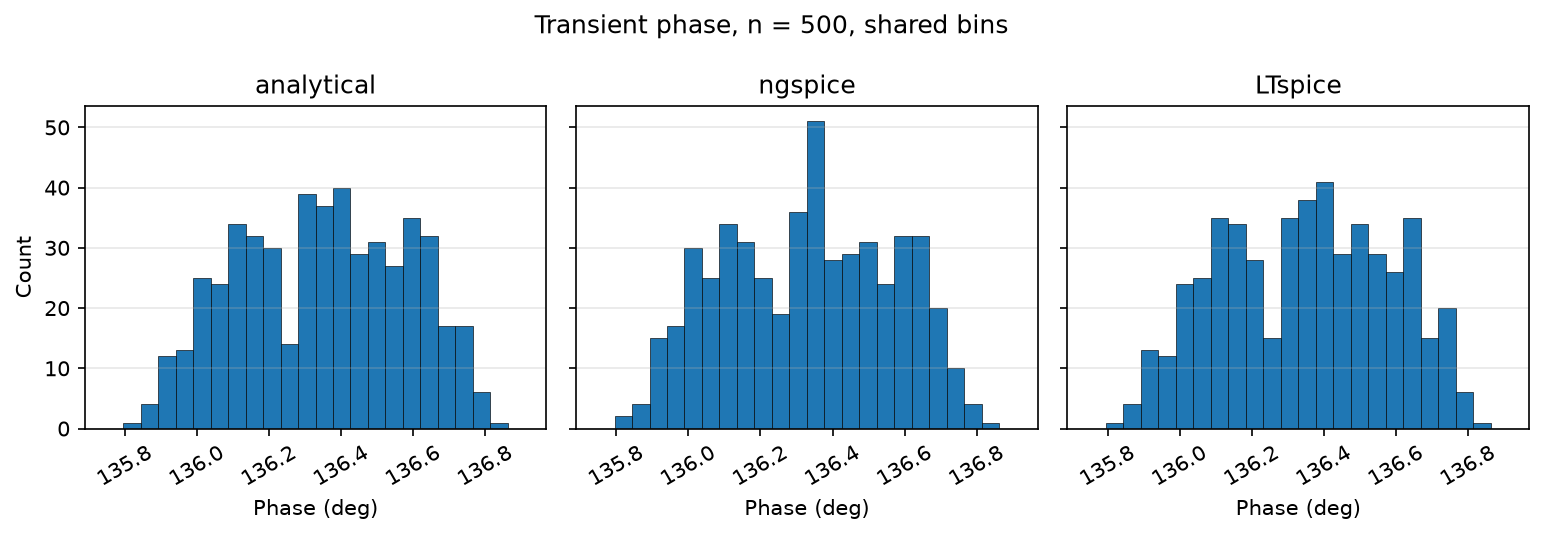

In [6]:
def shared_bins(cols, n=25):
    lo = min(float(tran[c].min()) for c in cols)
    hi = max(float(tran[c].max()) for c in cols)
    pad = 0.08 * (hi - lo if hi > lo else 1.0)
    return np.linspace(lo - pad, hi + pad, n)

def panel(cols, xlabel, title, fname, marks=None):
    bins = shared_bins(cols)
    fig, axes = plt.subplots(1, 3, figsize=(10.4, 3.6), sharex=True, sharey=True)
    labels = ("analytical", "ngspice", "LTspice")
    for ax, col, label in zip(axes, cols, labels):
        ax.hist(tran[col], bins=bins, color="C0", edgecolor="k", linewidth=0.3)
        ax.set_title(label)
        ax.tick_params(axis="x", labelrotation=30)
        ax.grid(True, axis="y", alpha=0.3)
        if marks:
            for value, style in marks:
                ax.axvline(value, color="C3", ls=style, lw=1.0)
    axes[0].set_ylabel("Count")
    for ax in axes:
        ax.set_xlabel(xlabel)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(FIG / fname, dpi=150)
    plt.show()

panel(
    ["an_gain", "ng_gain", "lt_gain"],
    "Gain at 250 kHz",
    f"Transient gain, n = {N_MC_TRAN}, shared bins",
    "05_mc_tran_gain.png",
    marks=[(float(hc["an_gain"].min()), "--"), (float(hc["an_gain"].max()), "--")],
)
panel(
    ["an_phase_deg", "ng_phase_deg", "lt_phase_deg"],
    "Phase (deg)",
    f"Transient phase, n = {N_MC_TRAN}, shared bins",
    "05_mc_tran_phase.png",
)
